# 04 · shRNA RNA-seq (ENCODE)

To see what QKI does to splicing, ENCODE knocked QKI down with a short hairpin RNA (shRNA) in K562 and HepG2 cells and sequenced their RNA. Control cells got a shRNA that targets nothing. Each condition has two replicates, so there are eight RNA-seq files (BAMs, aligned to the hg19 genome).

On Google Colab, run the next cell first in every session. It copies this repository onto the Colab machine and, with `SAVE_TO_DRIVE = True`, saves results and the figure to `My Drive/CS3_workflow` (Colab asks for permission to connect your Drive). `LITE = True` uses a small subset of the data that fits free Colab. On your own computer the cell does nothing.

In [ ]:
import sys

if "google.colab" in sys.modules:
    import os
    import subprocess
    REPO = "https://github.com/yeolab/encode-rbp-case-study"
    CLONE = "/content/encode-rbp-case-study"
    LITE = True    # True: small subset of the data, fits free Colab (about 1 h). False: all the data (5-8 h, ~50 GB)
    SAVE_TO_DRIVE = True    # results and the figure in My Drive/CS3_workflow; False: on this Colab machine only
    if not os.path.isdir(CLONE):
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO, CLONE], check=True)
    WORKFLOW = CLONE + "/notebooks/workflow"
    OUTPUT = None
    if SAVE_TO_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
        OUTPUT = "/content/drive/MyDrive/CS3_workflow"
    sys.path.insert(0, WORKFLOW)
    import colab_setup
    colab_setup.setup(WORKFLOW, lite=LITE, output_folder=OUTPUT)

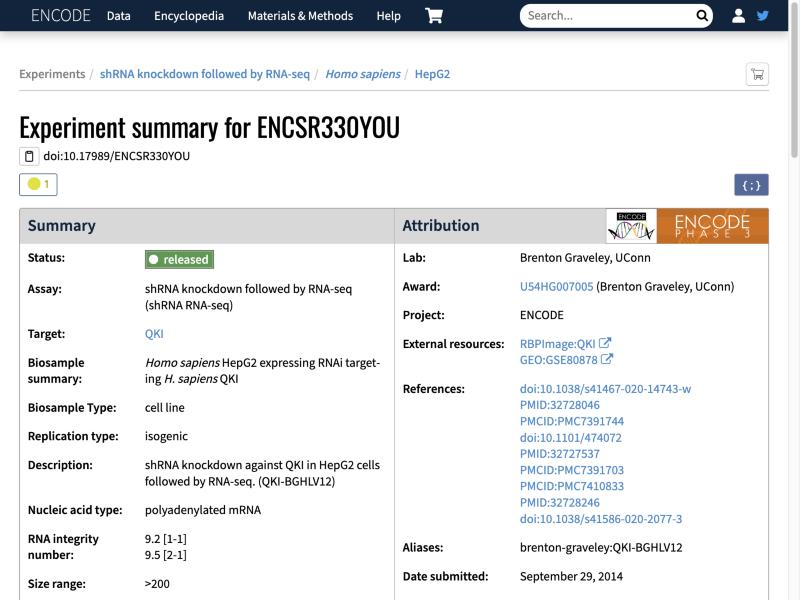

## Which BAMs

ENCODE's own splicing analysis (rMATS) records which BAMs it used. `knockdown_bams()` reads that list from the ENCODE API, so this notebook starts from the same files.

In [ ]:
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

sys.path.insert(0, ".")
import workflow_utils as U

ROOT, DATA = U.folders()
RESULTS = ROOT / "results" / "workflow"
API_CACHE = DATA / "downloads" / "rbpark_api"
print("case study folder:", ROOT)
print("data folder:", DATA)
import subprocess

ENCODE_CACHE = DATA / "downloads" / "encode_api"
BAM_DIR = DATA / "downloads" / "shrna_bams_hg19"
REF_DIR = DATA / "downloads" / "encode_reference"

In [ ]:
lineage = pd.concat([U.knockdown_bams(key, ENCODE_CACHE) for key in U.KNOCKDOWNS], ignore_index=True)
print("{:.0f} GB in all".format(lineage["file_size"].sum() / 1e9))
lineage[["knockdown", "condition", "rep", "experiment", "accession", "assembly", "read_length", "file_size"]]

Expected: K562 knockdown ENCFF280ZIB and ENCFF708KBX, control ENCFF092XAP and ENCFF265ZZB; HepG2 knockdown ENCFF610CID and ENCFF262GAC, control ENCFF755GKJ and ENCFF571ARP.

The next cell downloads them (about 40 GB) and indexes them. It checks each file's MD5 checksum, which takes about a minute per GB the first time. In lite mode it uses `lite_data/shrna/` instead: the same eight BAMs cut down to the reads on PICALM, a few MB each.

In [ ]:
paths = []
for _, row in lineage.iterrows():
    if U.LITE:
        paths.append(str(U.lite_shrna_bam(row["accession"])))
        continue
    out = BAM_DIR / (row["accession"] + ".bam")
    print("checking" if out.exists() else "downloading", row["knockdown"], row["condition"], "rep", row["rep"], out.name, flush=True)
    U.download_large(row["url"], out, row["file_size"], row["md5sum"], "md5")
    if not Path(str(out) + ".bai").exists():
        subprocess.check_call(["samtools", "index", str(out)])
    paths.append(str(out))
lineage["bam"] = paths
BAM_DIR.mkdir(parents=True, exist_ok=True)
lineage.to_csv(BAM_DIR / ("manifest_qki_lite.tsv" if U.LITE else "manifest_qki.tsv"), sep="\t", index=False)
lineage[["knockdown", "condition", "rep", "bam"]]

## How much QKI is left

ENCODE also measured gene expression in the same cells (DESeq2). The log2 fold change of QKI mRNA, knockdown vs control, shows how strong each knockdown is. ENCODE published two tables per knockdown, with and without batch normalization; this case study uses the one without.

In [ ]:
rows = []
for key, kd in U.KNOCKDOWNS.items():
    for role in ("deseq2", "deseq2_batch", "rmats"):
        U.encode_file(kd[role], REF_DIR, ENCODE_CACHE)
    rows.append({"knockdown": key,
                 "QKI log2FC": U.deseq2_log2fc(REF_DIR / (kd["deseq2"] + ".tsv"), kd["gene_id"]),
                 "QKI log2FC, batch-normalized": U.deseq2_log2fc(REF_DIR / (kd["deseq2_batch"] + ".tsv"), kd["gene_id"])})
level = pd.DataFrame(rows)
level["QKI mRNA left"] = (2 ** level["QKI log2FC"]).map("{:.0%}".format)
level.to_csv(RESULTS / "04_knockdown_level.tsv", sep="\t", index=False)
level

QKI mRNA drops to about 55% of control in K562 (log2 −0.85) and to about 10% in HepG2 (log2 −3.36). The HepG2 knockdown is much stronger, so the later notebooks lean on HepG2.